In [1]:
!pip install opencv-python


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import cv2
import matplotlib.pyplot as plt
import os


In [3]:
image = cv2.imread("SamplePhoto.jpg")


In [4]:
if image is None:
    print("Error: Image not found!")
else:
    print("Image loaded successfully.")


Image loaded successfully.


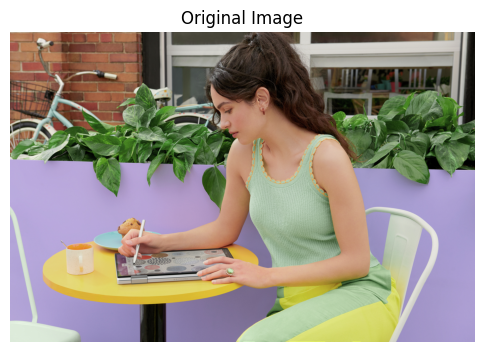

In [5]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [6]:
cv2.imwrite("Output_Image.jpg", image)
print("Image saved as Output_Image.jpg")


Image saved as Output_Image.jpg


In [7]:
cv2.imwrite("Image.png", image)
cv2.imwrite("Image.tiff", image)
cv2.imwrite("Image.bmp", image)

print("Image converted into PNG, TIFF and BMP.")


Image converted into PNG, TIFF and BMP.


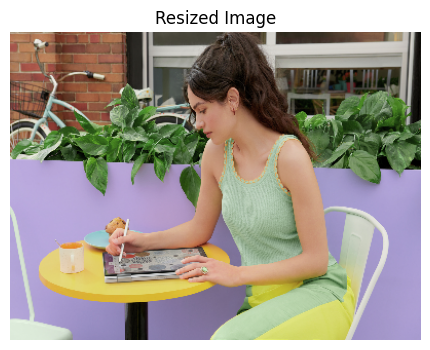

Resized image saved.


In [8]:
resized = cv2.resize(image, (400,300))

plt.figure(figsize=(6,4))
plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
plt.title("Resized Image")
plt.axis("off")
plt.show()

cv2.imwrite("Resized_Image.jpg", resized)
print("Resized image saved.")

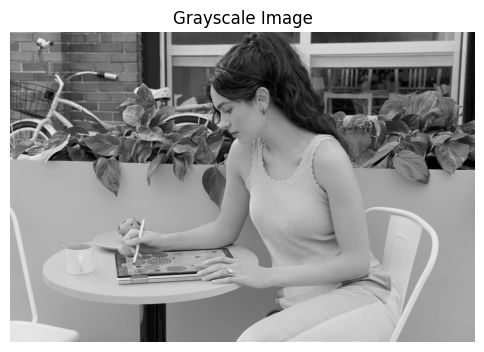

Grayscale image saved.


In [9]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(6,6))
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

cv2.imwrite("Gray_Image.jpg", gray)
print("Grayscale image saved.")



In [10]:
video_path = "SampleVideo.mp4"

if os.path.exists(video_path):

    cap = cv2.VideoCapture(video_path)

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        cv2.imshow("Video", frame)

        if cv2.waitKey(25) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()

else:
    print("SampleVideo.mp4 not found. Video section skipped.")



In [11]:
if os.path.exists(video_path):

    cap = cv2.VideoCapture(video_path)

    os.makedirs("Frames", exist_ok=True)

    count = 0

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        frame_name = f"Frames/frame_{count}.jpg"
        cv2.imwrite(frame_name, frame)

        count += 1

    cap.release()

    print(f"{count} frames extracted successfully into 'Frames' folder.")

else:
    print("Frame extraction skipped because SampleVideo.mp4 is missing.")

726 frames extracted successfully into 'Frames' folder.


In [12]:
import os
print(os.getcwd())

C:\Users\aarus\opencv


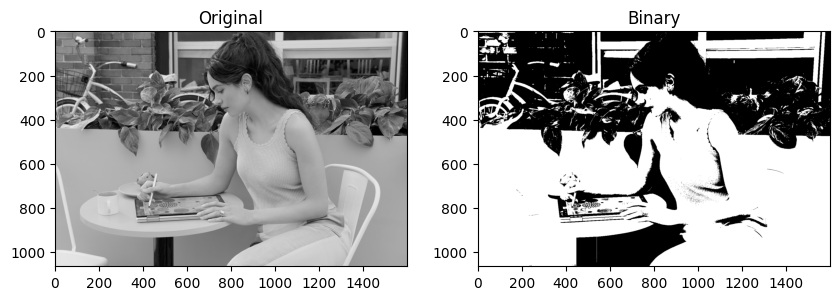

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("Gray_Image.jpg", cv2.IMREAD_GRAYSCALE)

threshold = np.mean(img)

binary = np.where(img >= threshold, 255, 0).astype(np.uint8)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title("Original")

plt.subplot(1,2,2)
plt.imshow(binary, cmap='gray')
plt.title("Binary")

plt.show()

Enter threshold value (0-255):  128


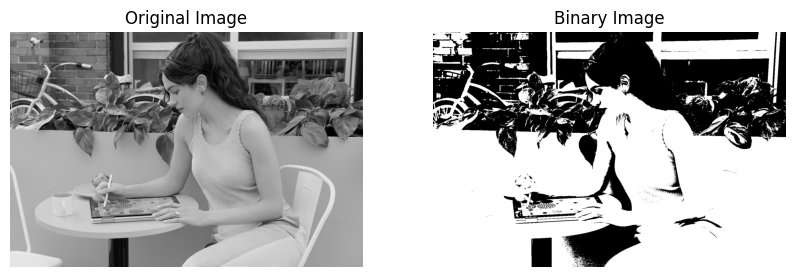

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("Gray_Image.jpg", cv2.IMREAD_GRAYSCALE)

threshold = int(input("Enter threshold value (0-255): "))

binary = np.where(img >= threshold, 255, 0).astype(np.uint8)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")

plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(binary, cmap='gray')
plt.title("Binary Image")
plt.axis("off")

plt.show()

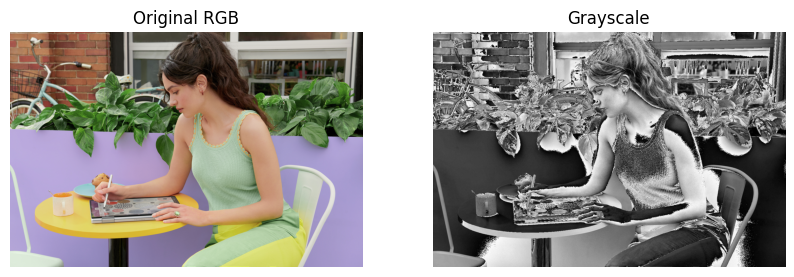

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("Image.png")

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

R = img[:, :, 0]
G = img[:, :, 1]
B = img[:, :, 2]

gray = ((R + G + B) / 3).astype(np.uint8)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original RGB")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(gray, cmap='gray')
plt.title("Grayscale")
plt.axis("off")

plt.show()

Enter Red weight:  0.7
Enter Green weight:  0.2
Enter Blue weight:  0.1


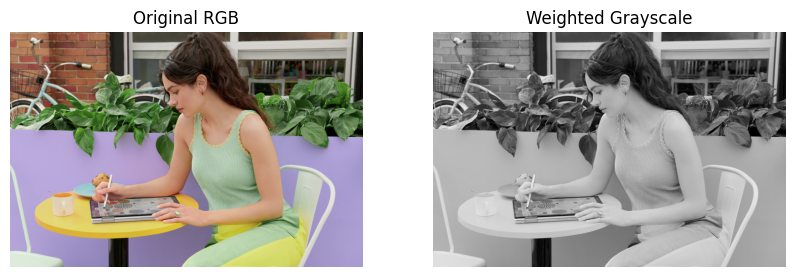

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("Image.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

wr = float(input("Enter Red weight: "))
wg = float(input("Enter Green weight: "))
wb = float(input("Enter Blue weight: "))

if abs((wr + wg + wb) - 1) < 1e-6 and 0 <= wr <= 1 and 0 <= wg <= 1 and 0 <= wb <= 1:

    R = img[:, :, 0]
    G = img[:, :, 1]
    B = img[:, :, 2]

    gray = (wr * R + wg * G + wb * B).astype(np.uint8)

    plt.figure(figsize=(10,5))

    plt.subplot(1,2,1)
    plt.imshow(img)
    plt.title("Original RGB")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(gray, cmap='gray')
    plt.title("Weighted Grayscale")
    plt.axis("off")

    plt.show()

else:
    print("Invalid weights! Sum must be 1.")